# CALPHAD agent: Scheil solidification

This demonstration uses an expert assistant, retrieval of TC-Python examples,
and a code-execution proxy. The original task requests share one conversation.

## Notes

> - Thermo-Calc 2024a with FEDEMO, TC-Python and an OpenAI API key are needed to run the calculations. Saved outputs can be inspected without them.
> - Both notebooks use the same agent preparation and `gpt-4o-2024-08-06` at temperature 0.3. New executions may differ.
> - The saved responses and outputs come from one verified execution. Notes identify essential units and assumptions; full conversations and generated scripts are linked below. Private installation paths are redacted.

## Agent setup

Follow the [setup instructions](README.md), then run the cells in order in a fresh kernel.
The reusable [agent setup](agent/agent_setup.py) and [system prompt](agent/prompts/minimal_v5.txt) are shared by both notebooks.


In [1]:
from pathlib import Path
from agent import start_demo

run, agents = start_demo("scheil", notebook=Path("scheil.ipynb").resolve())
run.show_setup()


Model: `gpt-4o-2024-08-06`; temperature: 0.3. [Recorded configuration](outputs/scheil/configuration.json).

## 1. Latent heat of solidification


In [2]:
question_1 = '\nTask:\nPerform a Scheil-calculation for the given alloy composition and plot the latent heat of solidification:\nFe - 1 wt-% C - 10 wt-% Cr\n\nPlease solve the task, save the result in a json file and plot it in a png file. \n'
print(question_1)



Task:
Perform a Scheil-calculation for the given alloy composition and plot the latent heat of solidification:
Fe - 1 wt-% C - 10 wt-% Cr

Please solve the task, save the result in a json file and plot it in a png file. 



2026-10-29 01:25:22,588 - autogen.agentchat.contrib.retrieve_user_proxy_agent - INFO - Found 28 chunks.


2026-10-29 01:25:22,610 - autogen.agentchat.contrib.vectordb.chromadb - INFO - No content embedding is provided. Will use the VectorDB's embedding function to generate the content embedding.


task1 : 8 messages; 4 saved files


The Scheil calculation for the Fe - 1 wt-% C - 10 wt-% Cr alloy was successfully executed using Thermo-Calc via `tc_python`. The latent heat of solidification was calculated and plotted as a function of temperature. Here are the key outcomes:

- **Results Saved:** The temperature and latent heat data were saved in a JSON file named `scheil_results.json`.
- **Plot Saved:** The plot of latent heat versus temperature was saved as a PNG file named `latent_heat_plot.png`.

These files contain the detailed results of the Scheil solidification simulation, providing insights into the latent heat changes during the solidification process of the specified alloy composition. If you need further analysis or have any questions, feel free to ask.

Executions: **1**; unsuccessful executions: **0**. [Full conversation](outputs/scheil/task1_conversation.json) · [Execution trace](outputs/scheil/task1_trace.txt). 

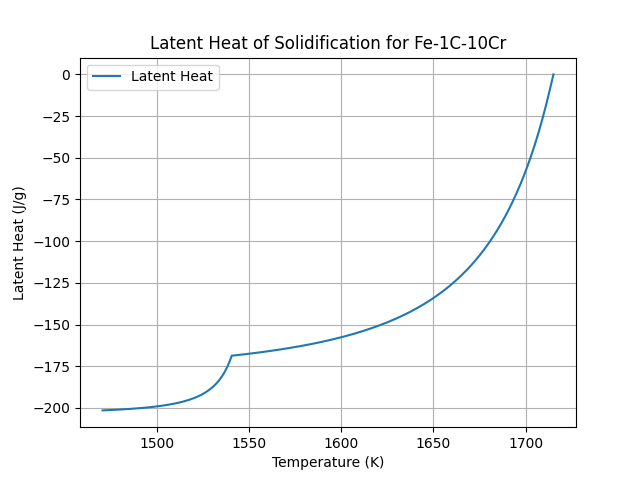

Saved data: [scheil_results.json](outputs/scheil/artifacts/task1/scheil_results.json)

In [3]:
# Start a fresh conversation with the first request.
agents.reset()
with run.task("task1", question_1):
    result_1 = agents.proxy_user.initiate_chat(
        agents.assistant, message=question_1, summary_method="reflection_with_llm"
    )
run.show_task("task1", agents.assistant, agents.proxy_user, finish=False)


> **Note.** The plotted heat is cumulative latent heat in J/g, with the solver’s sign convention.


## 2. Temperature at 80% solid


In [4]:
question_2 = '\nTask:\n\nFind the temperature where 80% is solidified as precisely as possible for the given composition:\nFe - 1 wt-% C - 10 wt-% Cr\n\nUse the function scipy.interpolate.interp1d\n\nPlease solve the task, save the result in a json file and plot it in a png file. \n'
print(question_2)



Task:

Find the temperature where 80% is solidified as precisely as possible for the given composition:
Fe - 1 wt-% C - 10 wt-% Cr

Use the function scipy.interpolate.interp1d

Please solve the task, save the result in a json file and plot it in a png file. 



task2 : 18 messages; 10 saved files


The script executed successfully, and the following outcomes were achieved:

- **Temperature at 80% Solidification:** The temperature at which 80% of the alloy is solidified was determined and saved in a JSON file named `solidification_temperature.json`.
- **Plot:** A plot showing the solid fraction as a function of temperature was created, with the 80% solidification point marked. This plot was saved as a PNG file named `solidification_plot.png`.

These files contain the detailed results of the Scheil solidification simulation for the specified alloy composition. If you need further analysis or have any questions, feel free to ask.

Executions: **2**; unsuccessful executions: **1**. [Full conversation](outputs/scheil/task2_conversation.json) · [Execution trace](outputs/scheil/task2_trace.txt). 

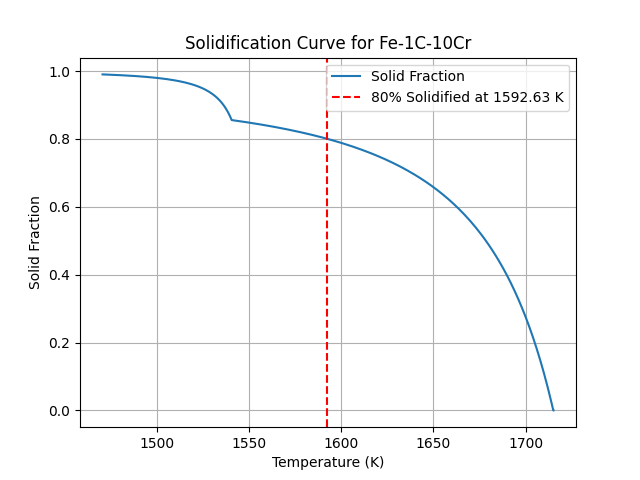

Saved data: [solidification_temperature.json](outputs/scheil/artifacts/task2/solidification_temperature.json)

**Saved results** (notebook formatting of the agent-generated file).

| temperature_at_80_solidification_K |
| --- |
| 1592.6324996067196 |

In [5]:
# Continue the same conversation with the second request.
with run.task("task2", question_2):
    agents.proxy_user.send(recipient=agents.assistant, message=question_2)
run.show_task("task2", agents.assistant, agents.proxy_user, finish=True)


> **Note.** The result is 1592.63 K at 80% solid by mole. Halving the calculation’s temperature step shifts the reference by 0.31 K.


## Resource use

Measured API tokens and estimated charges for this conversation.


In [6]:
run.show_usage()


| Task | Input tokens | Cached input¹ | Output tokens | Estimated USD² |
| --- | ---: | ---: | ---: | ---: |
| task1 | 51,352 | 19968 | 1,063 | 0.114050 |
| task2 | 147,156 | 91136 | 1,750 | 0.271470 |
| **Total** | **198,508** | **111,104** | **2,813** | **0.385520** |

¹ Cached input is included in input tokens. ² Estimated from returned API usage and [published rates](https://developers.openai.com/api/docs/models/gpt-4o); not an invoice. Includes the original task-1 LLM summary call. Retrieval embeddings and solver execution are local.